In [1]:
# Quick Test code cell to check if GPU is available and TensorFlow is installed correctly.
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

# Allocate GPU memory as needed instead of reserving most of it at startup.
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPUs detected:", gpus)
assert gpus, "No GPU detected: check your remote kernel and contact the server owner."

2026-10-30 14:18:08.596812: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-30 14:18:08.611299: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-30 14:18:08.615590: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-30 14:18:08.625569: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.17.0
GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1793369889.835989    2609 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1793369889.845148    2609 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1793369889.845295    2609 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


In [2]:
# Team members: ADD names and student IDs before submission.
# Full notebook execution: Not yet verified.
# Reused implementation sources: ADD any sources used before submission.

from pathlib import Path

# The notebook is in Model, so the dataset is one folder above it.
data_dir = Path("/shared-datasets/Dataset_32x32")
train_dir = data_dir / "Training"
test_dir = data_dir / "Test"

# Stop with a clear message if either dataset folder is missing.
assert train_dir.is_dir(), f"Training folder missing: {train_dir}"
assert test_dir.is_dir(), f"Test folder missing: {test_dir}"

# Class names come from the subfolders in each dataset.
class_names = sorted(p.name for p in train_dir.iterdir() if p.is_dir())
test_classes = sorted(p.name for p in test_dir.iterdir() if p.is_dir())

# Ignore capitalisation to account for BlackBerry / Blackberry.
train_labels = {name.casefold() for name in class_names}
test_labels = {name.casefold() for name in test_classes}

assert train_labels == test_labels, "Training and test classes differ."

# Count image files rather than folders or other files.
image_extensions = {".jpg", ".jpeg", ".png"}

def count_images(folder):
    return sum(
        p.is_file() and p.suffix.lower() in image_extensions
        for p in folder.rglob("*")
    )

print("Number of classes:", len(class_names))
print("Training images:", count_images(train_dir))
print("Test images:", count_images(test_dir))
print("Classes match when capitalisation is ignored:", train_labels == test_labels)

Number of classes: 274
Training images: 147416
Test images: 49106
Classes match when capitalisation is ignored: True


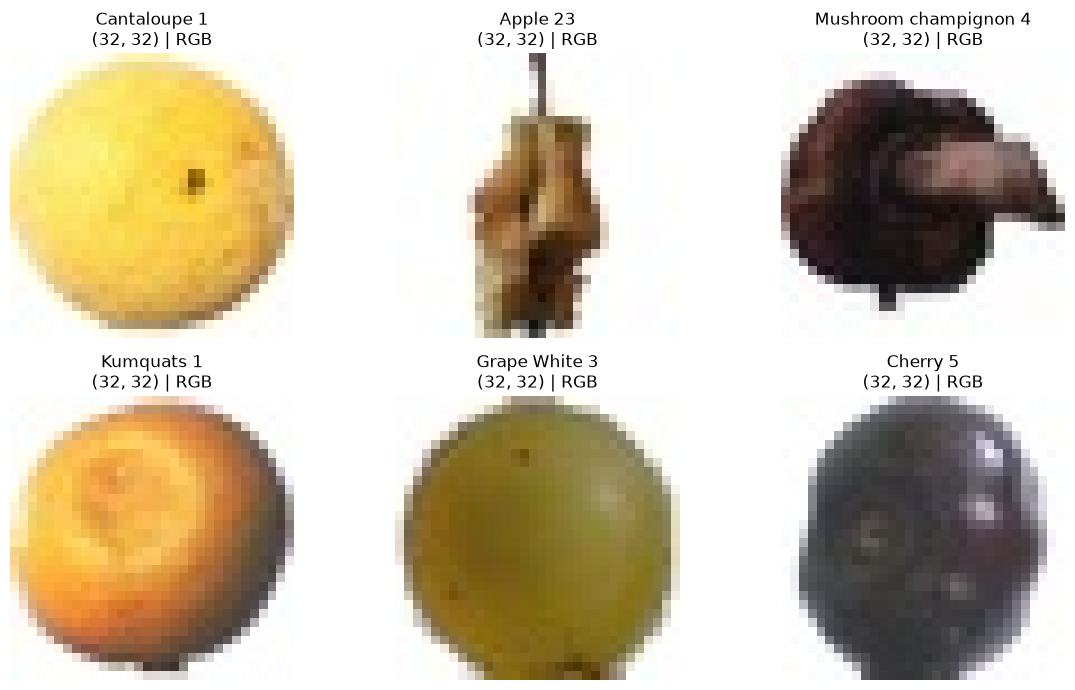

1. Create a reproducible 80/20 training–validation split and consistent labels.

In [4]:
import random
import tensorflow as tf

BATCH_SIZE = 32
SEED = 42
VALIDATION_SPLIT = 0.2

extensions = {".jpg", ".jpeg", ".png"}
class_to_index = {
    name.casefold(): index
    for index, name in enumerate(class_names)
}

# Handle naming differences such as BlackBerry / Blackberry.
test_folders = {
    folder.name.casefold(): folder
    for folder in test_dir.iterdir()
    if folder.is_dir()
}

assert len(class_to_index) == len(class_names), "Duplicate class names."
assert len(test_folders) == len(class_names)
assert set(test_folders) == set(class_to_index), "Classes do not match."

def get_image_paths(folder):
    return sorted(
        str(path)
        for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in extensions
    )

train_paths, train_labels = [], []
val_paths, val_labels = [], []
test_paths, test_labels = [], []

rng = random.Random(SEED)

for class_name in class_names:
    label = class_to_index[class_name.casefold()]
    paths = get_image_paths(train_dir / class_name)

    assert len(paths) >= 2, f"Too few training images: {class_name}"

    rng.shuffle(paths)
    n_val = max(1, min(len(paths) - 1,
                       int(len(paths) * VALIDATION_SPLIT)))

    val_paths.extend(paths[:n_val])
    val_labels.extend([label] * n_val)

    train_paths.extend(paths[n_val:])
    train_labels.extend([label] * (len(paths) - n_val))

    paths = get_image_paths(test_folders[class_name.casefold()])
    assert paths, f"No test images: {class_name}"

    test_paths.extend(paths)
    test_labels.extend([label] * len(paths))

assert set(train_paths).isdisjoint(val_paths)
assert set(train_paths + val_paths).isdisjoint(test_paths)

for labels in (train_labels, val_labels, test_labels):
    assert set(labels) == set(range(len(class_names)))

print("Classes:", len(class_names))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))

Classes: 274
Training images: 118025
Validation images: 29391
Test images: 49106


2. Decode, normalise and batch the images. Only training data is shuffled.

In [5]:
def load_image(path, label):
    image = tf.io.decode_image(
        tf.io.read_file(path),
        channels=3,
        expand_animations=False,
    )

    # Check the original size instead of silently resizing.
    tf.debugging.assert_equal(
        tf.shape(image),
        [32, 32, 3],
        message="Expected a 32×32 RGB image",
    )
    image = tf.ensure_shape(image, (32, 32, 3))

    # Convert uint8 [0, 255] to float32 [0, 1].
    image = tf.image.convert_image_dtype(image, tf.float32)

    return image, label


def make_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        tf.constant(paths, dtype=tf.string),
        tf.constant(labels, dtype=tf.int32),
    ))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    return (
        dataset
        .batch(BATCH_SIZE, drop_remainder=False)
        .prefetch(tf.data.AUTOTUNE)
    )


train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

I0000 00:00:1793369894.149351    2609 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1793369894.149514    2609 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1793369894.149614    2609 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1793369894.209264    2609 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

3. Verify dimensions, labels, normalisation and batch counts. This scans every image, so it may take a little time.

In [6]:
import math

def verify_dataset(name, dataset, expected_images):
    expected_batches = math.ceil(expected_images / BATCH_SIZE)
    assert int(dataset.cardinality().numpy()) == expected_batches

    image_count = 0

    for batch_index, (images, labels) in enumerate(dataset):
        expected_size = min(
            BATCH_SIZE,
            expected_images - batch_index * BATCH_SIZE,
        )

        tf.debugging.assert_type(images, tf.float32)
        tf.debugging.assert_type(labels, tf.int32)

        tf.debugging.assert_equal(
            tf.shape(images), [expected_size, 32, 32, 3]
        )
        tf.debugging.assert_equal(tf.shape(labels), [expected_size])

        tf.debugging.assert_all_finite(images, "Invalid pixel values")
        tf.debugging.assert_greater_equal(images, 0.0)
        tf.debugging.assert_less_equal(images, 1.0)

        tf.debugging.assert_greater_equal(labels, 0)
        tf.debugging.assert_less(labels, len(class_names))

        image_count += int(tf.shape(images)[0].numpy())

    assert image_count == expected_images

    print(
        f"{name}: verified {image_count:,} images "
        f"across {expected_batches:,} batches"
    )


verify_dataset("Training", train_ds, len(train_paths))
verify_dataset("Validation", val_ds, len(val_paths))
verify_dataset("Test", test_ds, len(test_paths))

images, labels = next(iter(val_ds))

print("\nImage batch:", images.shape, images.dtype)
print("Label batch:", labels.shape, labels.dtype)
print("Example classes:", [
    class_names[int(label)] for label in labels[:5].numpy()
])

2026-10-30 14:18:25.547659: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Training: verified 118,025 images across 3,689 batches


2026-10-30 14:18:28.069735: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Validation: verified 29,391 images across 919 batches
Test: verified 49,106 images across 1,535 batches

Image batch: (32, 32, 32, 3) <dtype: 'float32'>
Label batch: (32,) <dtype: 'int32'>
Example classes: ['Almonds 1', 'Almonds 1', 'Almonds 1', 'Almonds 1', 'Almonds 1']


4. Define residual blocks using convolutional layers, batch normalisation and skip connections.

In [7]:

from tensorflow.keras import layers, Model

def residual_block(x, filters, stride=1):
    shortcut = x

    y = layers.Conv2D(
        filters, kernel_size=3, strides=stride,
        padding="same", use_bias=False,
        kernel_initializer="he_normal"
    )(x)

    y = layers.BatchNormalization()(y)
    y = layers.ReLU()(y)

    y = layers.Conv2D(
        filters, kernel_size=3, strides=1,
        padding="same", use_bias=False,
        kernel_initializer="he_normal"
    )(y)

    y = layers.BatchNormalization()(y)

    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, kernel_size=1, strides=stride,
            padding="same", use_bias=False,
            kernel_initializer="he_normal"
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    y = layers.Add()([y, shortcut])

    return layers.ReLU()(y)


In [8]:
images, labels = next(iter(val_ds))

predictions = model(images, training=False)

print("Input shape:", images.shape)
print("Predictions shape:", predictions.shape)
print("Predicted classes:", tf.argmax(predictions, axis=1).numpy()[:5])
print("Actual classes:", labels.numpy()[:5])

NameError: name 'model' is not defined

5. Build a ResNet-20 architecture for 32×32 RGB images with 274 output classes.


In [ ]:
NUM_CLASSES = len(class_names)

assert NUM_CLASSES == 274, (
    f"Expected 274 classes, found {NUM_CLASSES}"
)

def build_resnet(input_shape=(32, 32, 3), num_classes=274):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(
        16, kernel_size=3, strides=1,
        padding="same", use_bias=False,
        kernel_initializer="he_normal"
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    for _ in range(3):
        x = residual_block(x, filters=16)

    x = residual_block(x, filters=32, stride=2)
    for _ in range(2):
        x = residual_block(x, filters=32)

    x = residual_block(x, filters=64, stride=2)
    for _ in range(2):
        x = residual_block(x, filters=64)

    x = layers.GlobalAveragePooling2D()(x)

    outputs = layers.Dense(
        num_classes, activation="softmax"
    )(x)

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="ResNet20_Fruits"
    )

model = build_resnet(
    input_shape=(32, 32, 3),
    num_classes=NUM_CLASSES
)

model.summary()

Model: "ResNet20_Fruits"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 32, 32,    │        432 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_19 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_19[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_20[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_23[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │ re_lu_19[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_21 (ReLU)     │ (None, 32, 32,    │          0 │ add_9[0][0]       │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_21[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_22 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_22[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_25[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 291,202 (1.11 MB)

 Trainable params: 289,634 (1.10 MB)

 Non-trainable params: 1,568 (6.12 KB)


6. Compile the ResNet model and verify its architecture, input dimensions and output predictions.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

assert model.input_shape == (None, 32, 32, 3)

assert model.output_shape == (None, NUM_CLASSES)

residual_additions = [
    layer for layer in model.layers
    if isinstance(layer, layers.Add)
]

assert len(residual_additions) == 9, (
    f"Expected 9 residual blocks, got {len(residual_additions)}"
)

images, labels = next(iter(val_ds))
predictions = model(images, training=False)

assert predictions.shape == (images.shape[0], NUM_CLASSES)
tf.debugging.assert_all_finite(
    predictions, "Predictions contain invalid values"
)

tf.debugging.assert_near(
    tf.reduce_sum(predictions, axis=1),
    tf.ones((images.shape[0],)),
    atol=1e-5
)

print("Model compiled successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Residual blocks:", len(residual_additions))
print("Prediction batch shape:", predictions.shape)
print("CNN005 architecture verification passed.")

Model compiled successfully.
Input shape: (None, 32, 32, 3)
Output shape: (None, 274)
Residual blocks: 9
Prediction batch shape: (32, 274)
CNN005 architecture verification passed.


6. Print Summaries of Best Model and Final Model

In [15]:
import tensorflow as tf

#load best and final models
best = tf.keras.models.load_model("training_runs/20261030_133948_938065/best_model.keras")
final = tf.keras.models.load_model("training_runs/20261030_133948_938065/final_model.keras")

#print model summaries
print("\nBest model summary:")
best.summary()
print("\nFinal model summary:")
final.summary()


Best model summary:


Model: "ResNet20_Fruits"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_63 (Conv2D)  │ (None, 32, 32,    │        432 │ input_layer_3[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_63[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_57 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_64 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_57[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_64[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_58 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_65 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_58[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_65[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_27 (Add)        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │ re_lu_57[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_59 (ReLU)     │ (None, 32, 32,    │          0 │ add_27[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_66 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_59[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_66[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_60 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_67 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_60[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_67[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_28 (Add)        │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 870,472 (3.32 MB)

 Trainable params: 289,634 (1.10 MB)

 Non-trainable params: 1,568 (6.12 KB)

... (4 outputs left out)

 Total params: 870,472 (3.32 MB)

 Trainable params: 289,634 (1.10 MB)

 Non-trainable params: 1,568 (6.12 KB)

 Optimizer params: 579,270 (2.21 MB)

7. Plot training and validation accuracy and loss across epochs

In [26]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load training history from CSV
history = pd.read_csv("model/training_runs/20261030_133948_938065/history.csv")

# Regular training history (30 epochs)
accuracy = history['accuracy']
loss = history['loss']
val_accuracy = history['val_accuracy']
val_loss = history['val_loss']

# Epoch numbers
epochs = range(1, len(accuracy) + 1)

# Create two plots
plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs, np.array(accuracy) * 100, label="Training Accuracy")
plt.plot(epochs, np.array(val_accuracy) * 100, label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("training_validation_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# Best validation results
best_epoch = np.argmax(val_accuracy) + 1

print(f"Best validation accuracy: {max(val_accuracy)*100:.4f}%")
print(f"Best validation loss: {min(val_loss):.6f}")
print(f"Best epoch: {best_epoch}")


ModuleNotFoundError: No module named 'pandas'

8. Evaluate trained ResNet model using the test dataset

In [ ]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (32, 32)  
BATCH_SIZE = 32

test_ds = tf.keras.utils.image_dataset_from_directory(
    "Dataset_32x32/Test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load the best model from regular training run
model = tf.keras.models.load_model(
    "model/training_runs/20261030_133948_938065/best_model.keras"
)

# Evaluate on test dataset
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("\n========== TEST RESULTS ==========")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

from sklearn.metrics import classification_report

# Get predictions
predictions = model.predict(test_ds)

# Predicted class labels
y_pred = np.argmax(predictions, axis=1)

# Actual class labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Get class names
class_names = test_ds.class_names

# Classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

NotFoundError: Could not find directory Dataset_32x32\Test